In [2]:
from google.colab import files

uploaded = files.upload()

Saving PlantVillage.zip to PlantVillage.zip


In [3]:
import zipfile
import os

zip_path = "/content/PlantVillage.zip"
extract_path = "/content/PlantVillage"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content")

print(os.listdir("/content/PlantVillage"))

['Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight']


Total Dataset Images: 2152

Class-wise Breakdown:
 - Potato___Early_blight: 1000 images
 - Potato___healthy: 152 images
 - Potato___Late_blight: 1000 images


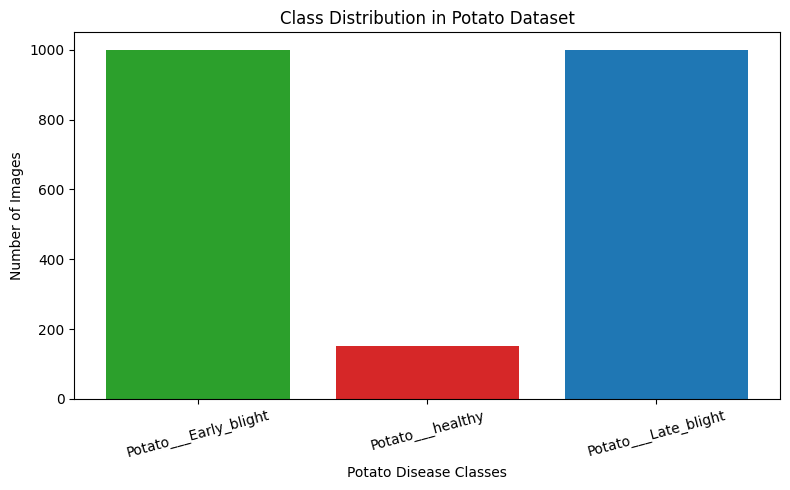

In [4]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

DATASET_DIR = "/content/PlantVillage"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
NUM_CLASSES = 3

# 1. BASIC EXPLORATORY DATA ANALYSIS (EDA)

class_counts = {}
total_images = 0

for class_name in os.listdir(DATASET_DIR):
    class_path = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_path):
        count = len(
            [
                f
                for f in os.listdir(class_path)
                if os.path.isfile(os.path.join(class_path, f))
            ]
        )
        class_counts[class_name] = count
        total_images += count

print(f"Total Dataset Images: {total_images}\n")
print("Class-wise Breakdown:")
for class_name, count in class_counts.items():
    print(f" - {class_name}: {count} images")

# Plot Class Distribution
plt.figure(figsize=(8, 5))
plt.bar(class_counts.keys(), class_counts.values(), color=["#2ca02c", "#d62728", "#1f77b4"])
plt.xlabel("Potato Disease Classes")
plt.ylabel("Number of Images")
plt.title("Class Distribution in Potato Dataset")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [5]:
# 2. DATA PIPELINE SETUP (AUTOTUNE + PREFETCH)

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=123,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
)

# Enable memory caching and hardware prefetching to maximize throughput
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)

Found 2152 files belonging to 3 classes.
Using 1722 files for training.
Found 2152 files belonging to 3 classes.
Using 430 files for validation.


In [6]:
# 3. MODEL 1: EfficientNetB3

def build_efficientnetb3():
    base_model = tf.keras.applications.EfficientNetB3(
        weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    base_model.trainable = False  # Freeze pre-trained weights for transfer learning

    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    # EfficientNet has built-in normalization
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES)(
        x
    )  # Raw logits for numerical stability

    model = models.Model(inputs, outputs, name="EfficientNetB3_Potato")
    return model


model_effnet = build_efficientnetb3()
model_effnet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

print("--- Training EfficientNetB3 ---")
history_effnet = model_effnet.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS
)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Training EfficientNetB3 ---
Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 101s 1s/step - accuracy: 0.7776 - loss: 0.5754 - val_accuracy: 0.8953 - val_loss: 0.2981
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 74ms/step - accuracy: 0.9204 - loss: 0.2501 - val_accuracy: 0.9302 - val_loss: 0.1975
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 75ms/step - accuracy: 0.9524 - loss: 0.1758 - val_accuracy: 0.9581 - val_loss: 0.1498
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 78ms/step - accuracy: 0.9628 - loss: 0.1396 - val_accuracy: 0.9721 - val_loss: 0.1267
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.9686 - loss: 0.1175 - val_accuracy: 0.9698 - val_loss: 0.1110


In [7]:
# 4. MODEL 2: DenseNet121

def build_densenet121():
    base_model = tf.keras.applications.DenseNet121(
        weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3)
    )
    base_model.trainable = False

    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    # Preprocess inputs specifically for DenseNet scaling
    x = tf.keras.applications.densenet.preprocess_input(inputs)
    x = base_model(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(NUM_CLASSES)(x)

    model = models.Model(inputs, outputs, name="DenseNet121_Potato")
    return model


model_densenet = build_densenet121()
model_densenet.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

print("--- Training DenseNet121 ---")
history_densenet = model_densenet.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS
)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
--- Training DenseNet121 ---
Epoch 1/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 72s 837ms/step - accuracy: 0.7770 - loss: 0.5295 - val_accuracy: 0.9186 - val_loss: 0.2782
Epoch 2/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 94ms/step - accuracy: 0.9024 - loss: 0.2655 - val_accuracy: 0.9326 - val_loss: 0.1959
Epoch 3/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.9326 - loss: 0.1968 - val_accuracy: 0.9512 - val_loss: 0.1615
Epoch 4/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 99ms/step - accuracy: 0.9361 - loss: 0.1672 - val_accuracy: 0.9605 - val_loss: 0.1364
Epoch 5/5
54/54 ━━━━━━━━━━━━━━━━━━━━ 5s 102ms/step - accuracy: 0.9460 - loss: 0.1397 - val_accuracy: 0.9651 - val_loss: 0.1222


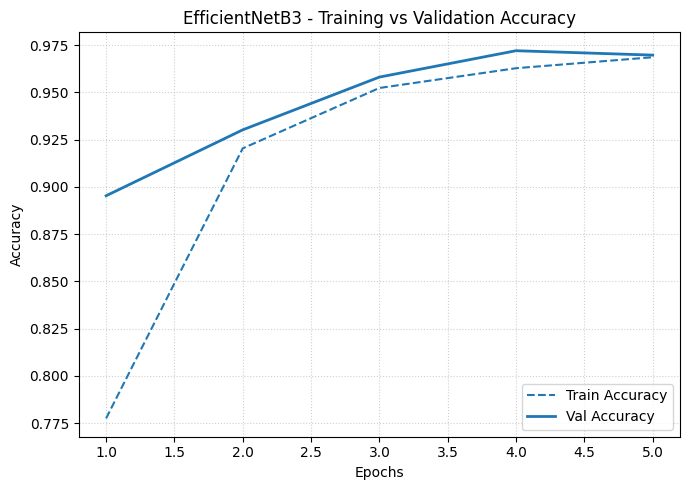

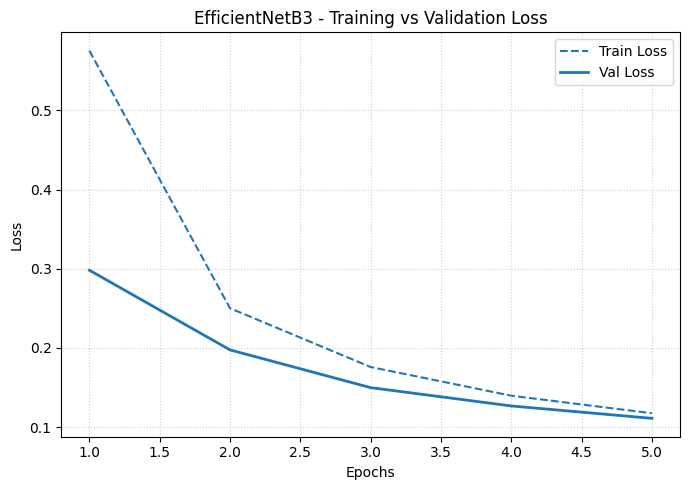

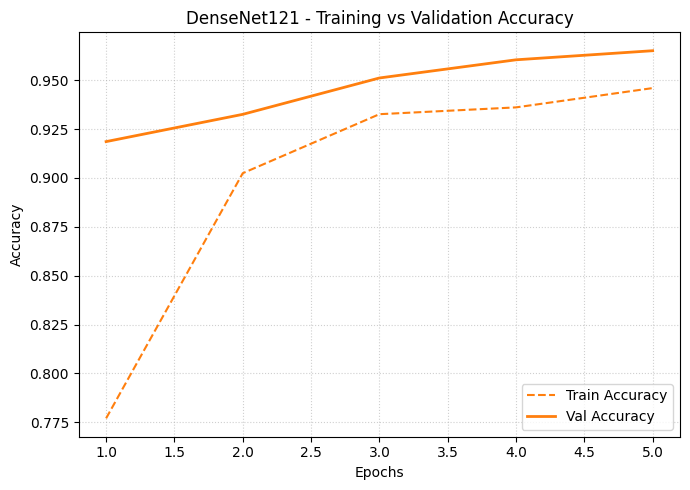

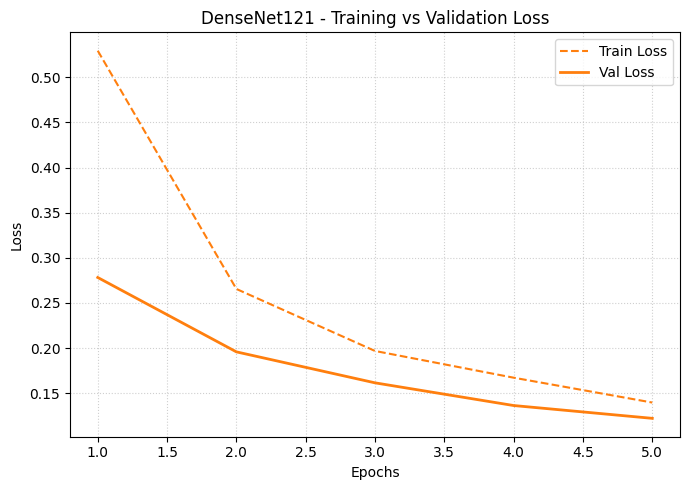

In [9]:
import matplotlib.pyplot as plt

epochs_range = range(1, EPOCHS + 1)

# 1. EFFICIENTNETB3 - ACCURACY PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history_effnet.history["accuracy"],
    label="Train Accuracy",
    color="#1f77b4",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history_effnet.history["val_accuracy"],
    label="Val Accuracy",
    color="#1f77b4",
    linewidth=2,
)
plt.title("EfficientNetB3 - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# 2. EFFICIENTNETB3 - LOSS PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history_effnet.history["loss"],
    label="Train Loss",
    color="#1f77b4",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history_effnet.history["val_loss"],
    label="Val Loss",
    color="#1f77b4",
    linewidth=2,
)
plt.title("EfficientNetB3 - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# 3. DENSENET121 - ACCURACY PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history_densenet.history["accuracy"],
    label="Train Accuracy",
    color="#ff7f0e",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history_densenet.history["val_accuracy"],
    label="Val Accuracy",
    color="#ff7f0e",
    linewidth=2,
)
plt.title("DenseNet121 - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# 4. DENSENET121 - LOSS PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history_densenet.history["loss"],
    label="Train Loss",
    color="#ff7f0e",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history_densenet.history["val_loss"],
    label="Val Loss",
    color="#ff7f0e",
    linewidth=2,
)
plt.title("DenseNet121 - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Configuration parameters
BATCH_SIZE = 32
IMAGE_SIZE = 224  # or 256 depending on dataset setup
CHANNELS = 3
n_classes = 3

# Preprocessing layer for resizing and rescaling
resize_and_rescale = tf.keras.Sequential(
    [
        layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
        layers.Rescaling(1.0 / 255),
    ]
)

# Input shape definition including batch dimension
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)

# Custom CNN Architecture
model = models.Sequential(
    [
        resize_and_rescale,
        layers.Conv2D(
            32, kernel_size=(3, 3), activation="relu", input_shape=input_shape
        ),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ]
)

# Build the model explicitly with input dimensions
model.build(input_shape=input_shape)

# Compile model for integer target labels
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

# Display network architecture summary
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (32, 224, 224, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (32, 222, 222, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (32, 111, 111, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (32, 109, 109, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (32, 54, 54, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (32, 52, 52, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (32, 26, 26, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (32, 24, 24, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (32, 12, 12, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (32, 10, 10, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (32, 5, 5, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (32, 3, 3, 64)         │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (32, 1, 1, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (32, 64)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (32, 64)               │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (32, 3)                │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171,459 (669.76 KB)

 Trainable params: 171,459 (669.76 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Hyperparameters
BATCH_SIZE = 32
IMAGE_SIZE = 224
CHANNELS = 3
n_classes = 3
EPOCHS = 10

# Input shape definition
input_shape = (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)

# Preprocessing layer
resize_and_rescale = tf.keras.Sequential(
    [
        layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
        layers.Rescaling(1.0 / 255),
    ]
)

# Custom CNN Model Architecture
model = models.Sequential(
    [
        resize_and_rescale,
        layers.Conv2D(
            32, kernel_size=(3, 3), activation="relu", input_shape=input_shape
        ),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(n_classes, activation="softmax"),
    ]
)

model.build(input_shape=input_shape)

# Compile model using Softmax outputs (from_logits=False)
model.compile(
    optimizer="adam",
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"],
)

# Execute Model Training
print("--- Training Custom CNN ---")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
)

--- Training Custom CNN ---
Epoch 1/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 23s 266ms/step - accuracy: 0.4593 - loss: 0.9212 - val_accuracy: 0.5651 - val_loss: 0.8678
Epoch 2/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.6161 - loss: 0.7777 - val_accuracy: 0.7302 - val_loss: 0.6225
Epoch 3/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - accuracy: 0.8264 - loss: 0.4399 - val_accuracy: 0.8744 - val_loss: 0.3197
Epoch 4/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 51ms/step - accuracy: 0.9065 - loss: 0.2613 - val_accuracy: 0.9047 - val_loss: 0.2470
Epoch 5/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9297 - loss: 0.1825 - val_accuracy: 0.8674 - val_loss: 0.3394
Epoch 6/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9425 - loss: 0.1550 - val_accuracy: 0.8163 - val_loss: 0.4890
Epoch 7/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 50ms/step - accuracy: 0.9245 - loss: 0.2015 - val_accuracy: 0.8628 - val_loss: 0.3406
Epoch 8/10
54/54 ━━━━━━━━━━━━━━━━━━━━ 3s 49ms/step - accuracy: 0.9646 - loss: 0.0

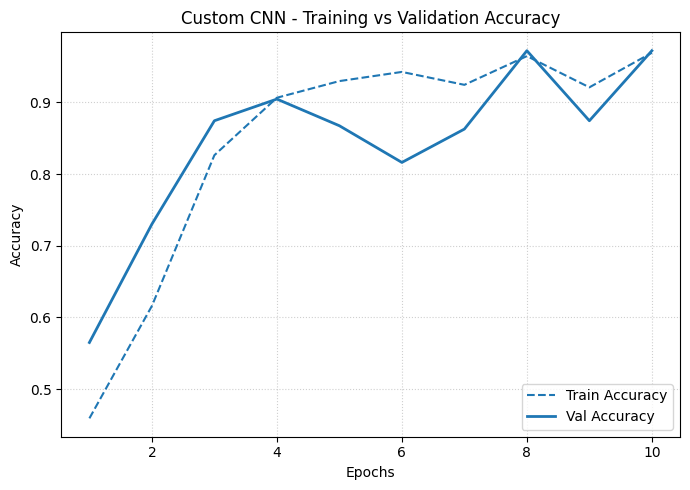

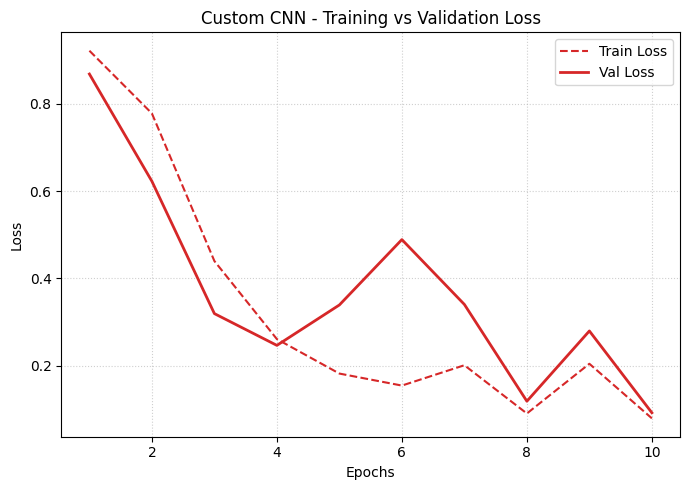

In [12]:
import matplotlib.pyplot as plt

# Execute after: history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
epochs_range = range(1, len(history.history["accuracy"]) + 1)

# 1. CUSTOM CNN - ACCURACY PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history.history["accuracy"],
    label="Train Accuracy",
    color="#1f77b4",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history.history["val_accuracy"],
    label="Val Accuracy",
    color="#1f77b4",
    linewidth=2,
)
plt.title("Custom CNN - Training vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# 2. CUSTOM CNN - LOSS PLOT
plt.figure(figsize=(7, 5))
plt.plot(
    epochs_range,
    history.history["loss"],
    label="Train Loss",
    color="#d62728",
    linestyle="--",
)
plt.plot(
    epochs_range,
    history.history["val_loss"],
    label="Val Loss",
    color="#d62728",
    linewidth=2,
)
plt.title("Custom CNN - Training vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend(loc="upper right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

--- Classification Report ---
                       precision    recall  f1-score   support

Potato___Early_blight     0.9851    0.9755    0.9803       204
 Potato___Late_blight     0.9602    0.9797    0.9698       197
     Potato___healthy     0.9630    0.8966    0.9286        29

             accuracy                         0.9721       430
            macro avg     0.9694    0.9506    0.9596       430
         weighted avg     0.9722    0.9721    0.9720       430



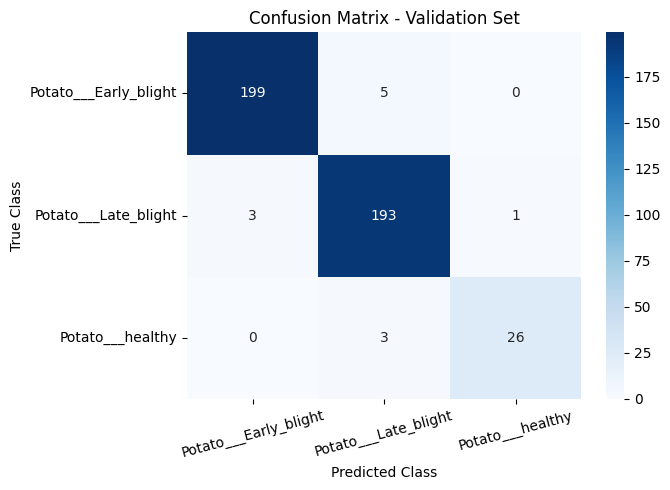

In [13]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Get true labels and model predictions for validation dataset
y_true = []
y_pred_probs = []

# Evaluate on validation dataset
for images, labels in val_ds:
    y_true.extend(labels.numpy())
    preds = model.predict(images, verbose=0)
    y_pred_probs.extend(preds)

y_true = np.array(y_true)
y_pred = np.argmax(np.array(y_pred_probs), axis=1)

# Class names mapping
class_names = ["Potato___Early_blight", "Potato___Late_blight", "Potato___healthy"]

# 1. Print Text Classification Report
print("--- Classification Report ---")
print(
    classification_report(
        y_true, y_pred, target_names=class_names, digits=4
    )
)

# 2. Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
)
plt.title("Confusion Matrix - Validation Set")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()